# Studi Kasus A/B Testing — Homepage Carousel TripNesia




## 1. Setup & Loading Data

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Load data
exp_log = pd.read_csv('mock_experimentation_log.csv')
carousel_log = pd.read_csv('mock_homepage_carousel_log.csv')

print("Log eksperimen   :", exp_log.shape)
print("Log carousel     :", carousel_log.shape)
exp_log.head()

Log eksperimen   : (88609, 5)
Log carousel     : (64877, 5)


,event_timestamp,unit_id,identified,interface,treatment
0,2021-05-05 00:33:56,m8wVa7J9I6XLoN6tAM3LZ9NsMu8=,True,mobile-android,"{""variant"":""alt_a""}"
1,2021-05-04 00:59:04,9RruApLe0crXh53rUU9ljHHyEOY=,True,mobile-android,"{""variant"":""alt_a""}"
2,2021-05-05 05:39:34,Du26/NtNvgOcgpPm4E0Lthzoidc=,True,mobile-android,"{""variant"":""alt_a""}"
3,2021-05-05 01:29:17,8qV/j7zQgIrHmalts2yh/dd6Z6w=,True,mobile-android,"{""variant"":""alt_a""}"
4,2021-05-05 02:56:30,S0loF0Ph8hDgrYDE9VzKaKvDg6I=,True,mobile-android,"{""variant"":""alt_a""}"


In [2]:
carousel_log.head()

,event_timestamp,unit_id,identified,interface,event_name
0,2021-05-03 09:33:26,XTWonw2gTxmthzKDYGMTU45wOwo=,True,mobile-iOS,CONTENTS SEEN
1,2021-05-03 09:33:41,XTWonw2gTxmthzKDYGMTU45wOwo=,True,mobile-iOS,CONTENTS SEEN
2,2021-05-03 09:33:46,XTWonw2gTxmthzKDYGMTU45wOwo=,True,mobile-iOS,CONTENTS SEEN
3,2021-05-03 11:09:12,4YT3XsLsIlpL0MOa7GhQaCWaPnE=,True,mobile-android,CONTENTS SEEN
4,2021-05-03 11:09:17,EzBTjz5Uo1aZOHD/mSRiraouBFs=,True,mobile-android,CONTENTS SEEN


## 2. Persiapan Data

In [3]:
# Parsing kolom JSON treatment
exp_log['variant'] = exp_log['treatment'].apply(lambda s: json.loads(s).get('variant'))
exp_log['event_timestamp'] = pd.to_datetime(exp_log['event_timestamp'])
carousel_log['event_timestamp'] = pd.to_datetime(carousel_log['event_timestamp'])

print("Distribusi varian (data mentah):")
print(exp_log['variant'].value_counts())
print(f"\nTotal baris alokasi      : {len(exp_log):,}")
print(f"Jumlah user unik         : {exp_log['unit_id'].nunique():,}")
print(f"Alokasi duplikat (ganda) : {len(exp_log) - exp_log['unit_id'].nunique():,}")

# Cek apakah ada user yang muncul dengan varian berbeda (bisa merusak randomisasi)
multi_variant_users = exp_log.groupby('unit_id')['variant'].nunique()
print(f"User dengan >1 varian    : {(multi_variant_users > 1).sum()}")

Distribusi varian (data mentah):
variant
alt_a      29768
alt_b      29540
control    29301
Name: count, dtype: int64

Total baris alokasi      : 88,609
Jumlah user unik         : 86,114
Alokasi duplikat (ganda) : 2,495


User dengan >1 varian    : 0


In [ ]:
# Ambil hanya alokasi PERTAMA per user
exp_log_u = (exp_log.sort_values('event_timestamp')
                    .drop_duplicates(subset='unit_id', keep='first')
                    .reset_index(drop=True))
print(f"Jumlah user setelah dedup: {len(exp_log_u):,}")
print("\nAlokasi final per varian:")
print(exp_log_u['variant'].value_counts())
print("\nProporsi:")
print(exp_log_u['variant'].value_counts(normalize=True).round(4))

Jumlah user setelah dedup: 86,114

Alokasi final per varian:
variant
alt_a      28923
alt_b      28719
control    28472
Name: count, dtype: int64

Proporsi:
variant
alt_a      0.3359
alt_b      0.3335
control    0.3306
Name: proportion, dtype: float64


In [5]:
# Gabungkan event carousel dengan timestamp alokasi, ambil hanya event post-allocation
merged = carousel_log.merge(
    exp_log_u[['unit_id', 'variant', 'event_timestamp']]
        .rename(columns={'event_timestamp': 'allocation_ts'}),
    on='unit_id', how='inner'
)
merged_valid = merged[merged['event_timestamp'] >= merged['allocation_ts']].copy()
print(f"Total event carousel             : {len(carousel_log):,}")
print(f"Event valid (post-allocation)    : {len(merged_valid):,}")

# Agregasi per user
seen     = merged_valid[merged_valid['event_name']=='CONTENTS SEEN'].groupby('unit_id').size().rename('n_seen')
engaged  = merged_valid[merged_valid['event_name']=='CONTENTS ENGAGED'].groupby('unit_id').size().rename('n_engaged')

user_df = (exp_log_u[['unit_id','variant','identified','interface']]
           .merge(seen, on='unit_id', how='left')
           .merge(engaged, on='unit_id', how='left'))
user_df['n_seen']    = user_df['n_seen'].fillna(0).astype(int)
user_df['n_engaged'] = user_df['n_engaged'].fillna(0).astype(int)
user_df['exposed']      = (user_df['n_seen']    > 0).astype(int)
user_df['engaged_user'] = (user_df['n_engaged'] > 0).astype(int)

user_df.head()

Total event carousel             : 64,877
Event valid (post-allocation)    : 64,868


,unit_id,variant,identified,interface,n_seen,n_engaged,exposed,engaged_user
0,fbNKvWU4WMdMzIGxy+UqySHZId8=,alt_b,True,mobile-android,0,0,0,0
1,DUJp/Ufdm8bkOiY2irF1xIzDH+E=,alt_b,True,mobile-android,0,0,0,0
2,nOPVdONJ+GIbfLbEUjBUXmaBgEI=,control,True,mobile-android,0,0,0,0
3,iihicJ0lGvMZ+6ZkgLlVkE4VcaA=,alt_b,True,mobile-iOS,3,0,1,0
4,B9xnk26y+gkA7/OuXGRqemEHVWM=,control,True,mobile-android,0,0,0,0


## 3. Sanity Checks

### 3.a Sample Ratio Mismatch (SRM)

In [6]:
obs = user_df['variant'].value_counts().sort_index()
exp = np.array([len(user_df)/3]*3)
chi2, p_srm = stats.chisquare(obs.values, exp)
print(f"Jumlah observasi : {dict(obs)}")
print(f"Jumlah harapan   : {dict(zip(obs.index, exp.astype(int)))}")
print(f"Chi-square       : {chi2:.4f}")
print(f"p-value          : {p_srm:.4f}")
print(f"=> {'LOLOS — tidak ada SRM' if p_srm > 0.01 else 'GAGAL — terdeteksi SRM, investigasi randomisasi!'}")

Jumlah observasi : {'alt_a': np.int64(28923), 'alt_b': np.int64(28719), 'control': np.int64(28472)}
Jumlah harapan   : {'alt_a': np.int64(28704), 'alt_b': np.int64(28704), 'control': np.int64(28704)}
Chi-square       : 3.5537
p-value          : 0.1692
=> LOLOS — tidak ada SRM


### 3.b Balance Dimensi

In [7]:
print("Proporsi interface per varian:")
print(pd.crosstab(user_df['variant'], user_df['interface'], normalize='index').round(3))
print("\nProporsi identified per varian:")
print(pd.crosstab(user_df['variant'], user_df['identified'], normalize='index').round(3))

Proporsi interface per varian:


interface  mobile-android  mobile-iOS
variant                              
alt_a               0.781       0.219
alt_b               0.779       0.221
control             0.784       0.216

Proporsi identified per varian:
identified  False  True 
variant                 
alt_a       0.109  0.891
alt_b       0.103  0.897
control     0.107  0.893


## 4. Exploratory Analysis & Uji Statistik

### 4.a Ringkasan Level Varian

In [8]:
summary = user_df.groupby('variant').agg(
    users          = ('unit_id', 'count'),
    exposed_users  = ('exposed', 'sum'),
    engaged_users  = ('engaged_user', 'sum'),
    total_seen     = ('n_seen', 'sum'),
    total_engaged  = ('n_engaged', 'sum'),
).reset_index()

summary['exposure_rate']      = summary['exposed_users']  / summary['users']
summary['engagement_overall'] = summary['engaged_users']  / summary['users']
summary['CTR_user_level']     = summary['engaged_users']  / summary['exposed_users']     # OEC
summary['CTR_event_level']    = summary['total_engaged']  / summary['total_seen']        # guardrail

summary.round(5)

,variant,users,exposed_users,engaged_users,total_seen,total_engaged,exposure_rate,engagement_overall,CTR_user_level,CTR_event_level
0,alt_a,28923,10792,1113,20019,1704,0.37313,0.03848,0.10313,0.08512
1,alt_b,28719,10858,993,20134,1523,0.37808,0.03458,0.09145,0.07564
2,control,28472,11791,644,20566,922,0.41413,0.02262,0.05462,0.04483


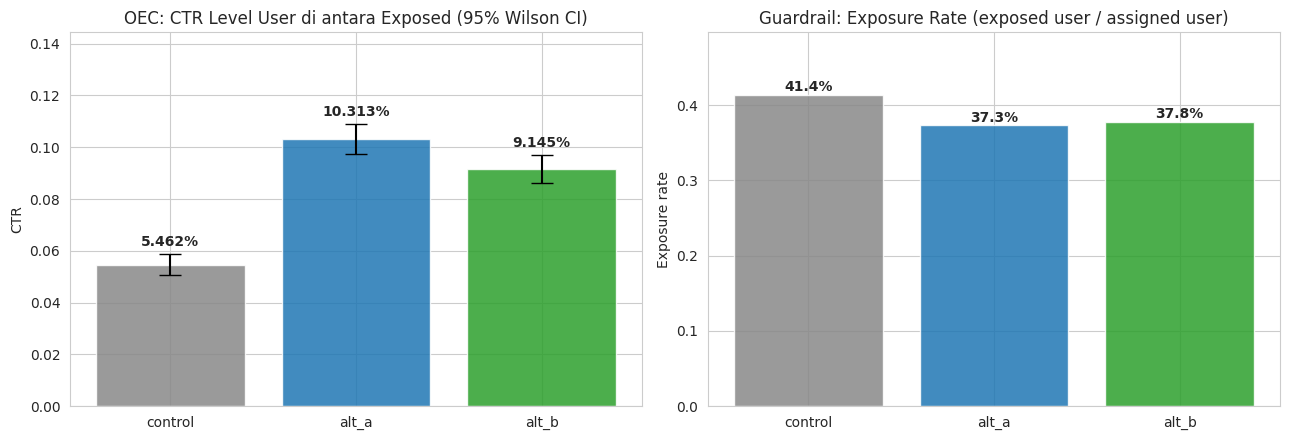

In [9]:
# Visualisasi OEC per varian dengan 95% CI
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# CTR user-level + Wilson CI
order = ['control', 'alt_a', 'alt_b']
ctrs, lows, highs = [], [], []
for v in order:
    row = summary[summary['variant']==v].iloc[0]
    ctr = row['engaged_users'] / row['exposed_users']
    lo, hi = proportion_confint(row['engaged_users'], row['exposed_users'], alpha=0.05, method='wilson')
    ctrs.append(ctr); lows.append(ctr-lo); highs.append(hi-ctr)

ax = axes[0]
colors = ['#888888', '#1f77b4', '#2ca02c']
ax.bar(order, ctrs, yerr=[lows, highs], capsize=8, color=colors, alpha=0.85)
for i, c in enumerate(ctrs):
    ax.text(i, c + highs[i] + 0.003, f'{c:.3%}', ha='center', fontweight='bold')
ax.set_title('OEC: CTR Level User di antara Exposed (95% Wilson CI)')
ax.set_ylabel('CTR'); ax.set_ylim(0, max(ctrs)*1.4)

# Exposure rate per varian
ax = axes[1]
expr = [summary[summary['variant']==v]['exposure_rate'].iloc[0] for v in order]
ax.bar(order, expr, color=colors, alpha=0.85)
for i, e in enumerate(expr):
    ax.text(i, e + 0.005, f'{e:.1%}', ha='center', fontweight='bold')
ax.set_title('Guardrail: Exposure Rate (exposed user / assigned user)')
ax.set_ylabel('Exposure rate'); ax.set_ylim(0, max(expr)*1.2)

plt.tight_layout(); plt.show()

### 4.b Uji Statistik — Two-Proportion Z-Test

In [10]:
def ztest_pair(s, a, b, num_col, den_col):
    ra = s[s['variant']==a].iloc[0]
    rb = s[s['variant']==b].iloc[0]
    counts = np.array([ra[num_col], rb[num_col]])
    nobs   = np.array([ra[den_col], rb[den_col]])
    z, p = proportions_ztest(counts, nobs)
    pa, pb = counts[0]/nobs[0], counts[1]/nobs[1]
    # Pooled SE untuk CI perbedaan
    pooled = (counts.sum())/(nobs.sum())
    se_diff = np.sqrt(pa*(1-pa)/nobs[0] + pb*(1-pb)/nobs[1])
    diff = pb - pa
    ci_lo, ci_hi = diff - 1.96*se_diff, diff + 1.96*se_diff
    return {'comparison': f'{b} vs {a}', f'rate_{a}': pa, f'rate_{b}': pb,
            'abs_diff': diff, 'rel_lift_%': diff/pa*100,
            'CI95_low': ci_lo, 'CI95_high': ci_hi, 'z': z, 'p_value': p}

print("=== OEC: CTR Level User (engaged_users / exposed_users) ===")
oec_results = pd.DataFrame([
    ztest_pair(summary, 'control', 'alt_a', 'engaged_users', 'exposed_users'),
    ztest_pair(summary, 'control', 'alt_b', 'engaged_users', 'exposed_users'),
    ztest_pair(summary, 'alt_a',   'alt_b', 'engaged_users', 'exposed_users'),
])
oec_results.round(5)

=== OEC: CTR Level User (engaged_users / exposed_users) ===


,comparison,rate_control,rate_alt_a,abs_diff,rel_lift_%,CI95_low,CI95_high,z,p_value,rate_alt_b
0,alt_a vs control,0.05462,0.10313,0.04851,88.82435,0.04146,0.05557,-13.59551,0.00000,NaN
1,alt_b vs control,0.05462,NaN,0.03684,67.44192,0.03004,0.04363,-10.69503,0.00000,0.09145
2,alt_b vs alt_a,NaN,0.10313,-0.01168,-11.32398,-0.01957,-0.00378,2.89942,0.00374,0.09145


In [11]:
print("=== Guardrail: Event-level CTR (engaged_events / seen_events) ===")
event_results = pd.DataFrame([
    ztest_pair(summary, 'control', 'alt_a', 'total_engaged', 'total_seen'),
    ztest_pair(summary, 'control', 'alt_b', 'total_engaged', 'total_seen'),
    ztest_pair(summary, 'alt_a',   'alt_b', 'total_engaged', 'total_seen'),
])
event_results.round(5)

=== Guardrail: Event-level CTR (engaged_events / seen_events) ===


,comparison,rate_control,rate_alt_a,abs_diff,rel_lift_%,CI95_low,CI95_high,z,p_value,rate_alt_b
0,alt_a vs control,0.04483,0.08512,0.04029,89.86553,0.03550,0.04508,-16.49485,0.00000,NaN
1,alt_b vs control,0.04483,NaN,0.03081,68.72862,0.02619,0.03543,-13.07893,0.00000,0.07564
2,alt_b vs alt_a,NaN,0.08512,-0.00948,-11.13257,-0.01479,-0.00416,3.49222,0.00048,0.07564


In [12]:
alpha_bonf = 0.05/3
print(f"Alpha terkoreksi Bonferroni: {alpha_bonf:.4f}\n")
print("Keputusan (OEC, CTR level user):")
for _, r in oec_results.iterrows():
    sig = "TOLAK H0" if r['p_value'] < alpha_bonf else "Gagal tolak H0"
    print(f"  {r['comparison']:<22}  p={r['p_value']:.2e}  lift={r['rel_lift_%']:+.2f}%   => {sig}")

Alpha terkoreksi Bonferroni: 0.0167

Keputusan (OEC, CTR level user):
  alt_a vs control        p=4.26e-42  lift=+88.82%   => TOLAK H0
  alt_b vs control        p=1.07e-26  lift=+67.44%   => TOLAK H0
  alt_b vs alt_a          p=3.74e-03  lift=-11.32%   => TOLAK H0


### 4.c Analisis Segmentasi

In [13]:
def seg_summary(df, by):
    seg = (df[df['exposed']==1]
           .groupby(['variant', by])
           .agg(exposed=('exposed','sum'),
                engaged=('engaged_user','sum')).reset_index())
    seg['CTR'] = seg['engaged']/seg['exposed']
    return seg

seg_iface = seg_summary(user_df, 'interface')
seg_iface.round(4)

,variant,interface,exposed,engaged,CTR
0,alt_a,mobile-android,8618,870,0.1010
1,alt_a,mobile-iOS,2174,242,0.1113
2,alt_b,mobile-android,8696,785,0.0903
3,alt_b,mobile-iOS,2162,208,0.0962
4,control,mobile-android,9471,515,0.0544
5,control,mobile-iOS,2320,128,0.0552


In [14]:
seg_id = seg_summary(user_df, 'identified')
seg_id.round(4)

,variant,identified,exposed,engaged,CTR
0,alt_a,False,345,30,0.0870
1,alt_a,True,10447,1082,0.1036
2,alt_b,False,307,15,0.0489
3,alt_b,True,10551,978,0.0927
4,control,False,1453,56,0.0385
5,control,True,10338,587,0.0568


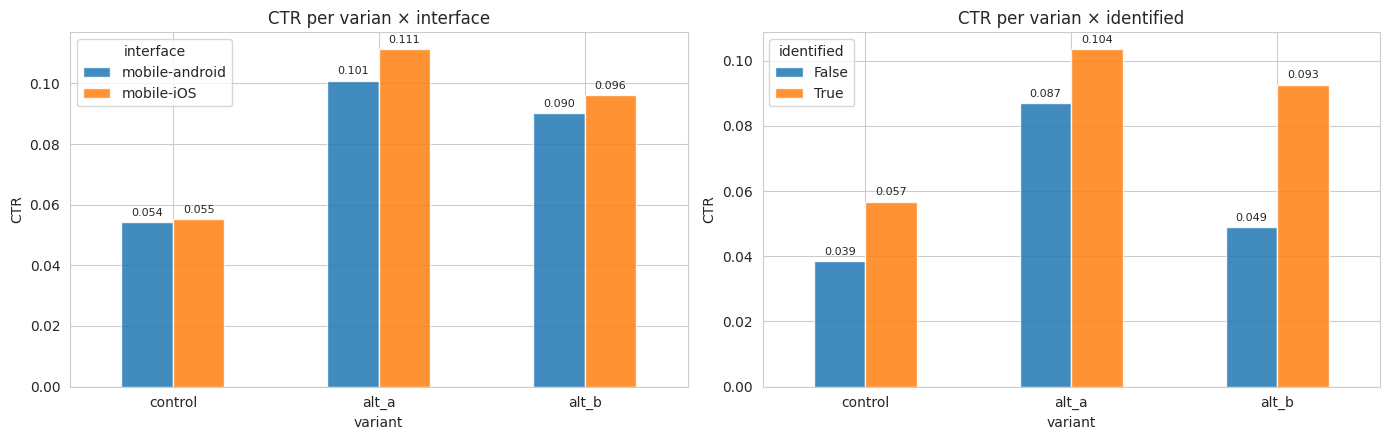

In [15]:
# Visualisasi CTR per segmen
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, seg, by, title in [
    (axes[0], seg_iface, 'interface',  'CTR per varian × interface'),
    (axes[1], seg_id,    'identified', 'CTR per varian × identified')
]:
    pivot = seg.pivot(index='variant', columns=by, values='CTR').loc[['control','alt_a','alt_b']]
    pivot.plot(kind='bar', ax=ax, color=['#1f77b4','#ff7f0e'], alpha=0.85)
    ax.set_title(title); ax.set_ylabel('CTR'); ax.tick_params(axis='x', rotation=0)
    for c in ax.containers:
        ax.bar_label(c, fmt='%.3f', padding=3, fontsize=8)

plt.tight_layout(); plt.show()

### 4.d Cek Robustness dan Guardrail Exposure Rate

In [16]:
print("=== Exposure rate (exposed_users / assigned_users) ===")
exp_results = pd.DataFrame([
    ztest_pair(summary, 'control', 'alt_a', 'exposed_users', 'users'),
    ztest_pair(summary, 'control', 'alt_b', 'exposed_users', 'users'),
])
exp_results.round(5)

=== Exposure rate (exposed_users / assigned_users) ===


,comparison,rate_control,rate_alt_a,abs_diff,rel_lift_%,CI95_low,CI95_high,z,p_value,rate_alt_b
0,alt_a vs control,0.41413,0.37313,-0.04100,-9.89976,-0.04899,-0.03301,10.05240,0.0,NaN
1,alt_b vs control,0.41413,NaN,-0.03605,-8.70482,-0.04406,-0.02804,8.81356,0.0,0.37808


In [17]:
print("=== ITT-style: engaged users / all assigned users ===")
itt_results = pd.DataFrame([
    ztest_pair(summary, 'control', 'alt_a', 'engaged_users', 'users'),
    ztest_pair(summary, 'control', 'alt_b', 'engaged_users', 'users'),
    ztest_pair(summary, 'alt_a',   'alt_b', 'engaged_users', 'users'),
])
itt_results.round(5)

=== ITT-style: engaged users / all assigned users ===


,comparison,rate_control,rate_alt_a,abs_diff,rel_lift_%,CI95_low,CI95_high,z,p_value,rate_alt_b
0,alt_a vs control,0.02262,0.03848,0.01586,70.13119,0.01305,0.01867,-11.02999,0.00000,NaN
1,alt_b vs control,0.02262,NaN,0.01196,52.86640,0.00923,0.01469,-8.57478,0.00000,0.03458
2,alt_b vs alt_a,NaN,0.03848,-0.00391,-10.14793,-0.00697,-0.00084,2.49855,0.01247,0.03458
